Device: cuda

Classes:
0 : Central Serous Chorioretinopathy (Color Fundus)
1 : Diabetic Retinopathy
2 : Disc Edema
3 : Glaucoma
4 : Healthy
5 : Macular Scar
6 : Myopia
7 : Pterygium
8 : Retinal Detachment
9 : Retinitis Pigmentosa

Number of classes: 10

Total images: 5335

Dataset Split:
Train: 3734
Validation: 800
Test: 801
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 190MB/s] 



Model:
Linear(in_features=2048, out_features=10, bias=True)

Starting End-to-End ResNet50 Training...


Epoch 1/50


Train Acc: 0.5886 | Train Loss: 1.2462 | Val Acc: 0.6850 | Val Loss: 0.8936
Best model updated: Val Acc = 0.6850

Epoch 2/50


Train Acc: 0.7477 | Train Loss: 0.7134 | Val Acc: 0.7350 | Val Loss: 0.7092
Best model updated: Val Acc = 0.7350

Epoch 3/50


Train Acc: 0.7978 | Train Loss: 0.5489 | Val Acc: 0.7462 | Val Loss: 0.6896
Best model updated: Val Acc = 0.7462

Epoch 4/50


... (43 outputs left out)

Train Acc: 0.9221 | Train Loss: 0.1288 | Val Acc: 0.7350 | Val Loss: 1.6326

Epoch 48/50


Train Acc: 0.9226 | Train Loss: 0.1373 | Val Acc: 0.7250 | Val Loss: 1.6497

Epoch 49/50


Train Acc: 0.9181 | Train Loss: 0.1353 | Val Acc: 0.7438 | Val Loss: 1.6691

Epoch 50/50


Train Acc: 0.9215 | Train Loss: 0.1218 | Val Acc: 0.7275 | Val Loss: 1.8964


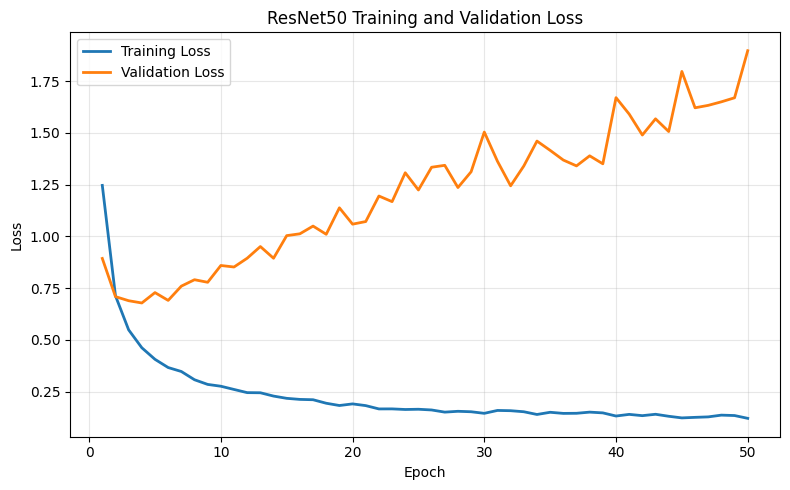


Best Validation Accuracy: 0.7662



END-TO-END RESNET50 BASELINE RESULTS

Validation Results:
Accuracy : 0.7662
Precision: 0.7925
Recall   : 0.7670
F1-score : 0.7701
Log Loss : 0.7599

Classification Report - Validation Set:

                                                 precision    recall  f1-score   support

Central Serous Chorioretinopathy (Color Fundus)       0.63      0.80      0.71        15
                           Diabetic Retinopathy       0.92      0.91      0.91       226
                                     Disc Edema       0.88      0.74      0.80        19
                                       Glaucoma       0.72      0.72      0.72       202
                                        Healthy       0.69      0.79      0.74       153
                                   Macular Scar       0.61      0.78      0.68        67
                                         Myopia       0.73      0.40      0.52        75
                                      Pterygium       1.00      1.00      1.00         3
       

In [ ]:
# END-TO-END RESNET50 BASELINE
# Same dataset split + preprocessing/augmentation + evaluation

import os
import gc
import random
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# SETTINGS

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32

# Number of training epochs
EPOCHS = 50

# Learning rate
LR = 1e-4

NUM_WORKERS = 4

print("Device:", DEVICE)

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Optional deterministic settings
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# DATASET

class ImageDataset(Dataset):

    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = np.array(file_paths)
        self.labels = np.array(labels)
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):

        img = Image.open(self.file_paths[idx]).convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return img, label


# TRANSFORMATIONS

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# LOAD DATASET

DATA_PATH = "/kaggle/input/datasets/sabrina001/eye-disease-image-dataset/Original Dataset"

CLASSES = sorted([
    d for d in os.listdir(DATA_PATH)
    if os.path.isdir(os.path.join(DATA_PATH, d))
])

print("\nClasses:")
for i, cls in enumerate(CLASSES):
    print(i, ":", cls)

NUM_CLASSES = len(CLASSES)

print("\nNumber of classes:", NUM_CLASSES)


file_paths = []
labels = []

for idx, cls in enumerate(CLASSES):

    cls_path = os.path.join(DATA_PATH, cls)

    for f in os.listdir(cls_path):

        if f.lower().endswith(
            (".png", ".jpg", ".jpeg")
        ):
            file_paths.append(
                os.path.join(cls_path, f)
            )
            labels.append(idx)


file_paths = np.array(file_paths)
labels = np.array(labels)

print("\nTotal images:", len(file_paths))


# TRAIN / VALIDATION / TEST SPLIT

X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("\nDataset Split:")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


# DATASETS

train_dataset = ImageDataset(
    X_train,
    y_train,
    transform=train_transform
)

val_dataset = ImageDataset(
    X_val,
    y_val,
    transform=val_test_transform
)

test_dataset = ImageDataset(
    X_test,
    y_test,
    transform=val_test_transform
)


# DATALOADERS

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# RESNET50 (END-TO-END TRAINING)

weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

print("\nModel:")
print(model.fc)


# LOSS + OPTIMIZER

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR
)


# TRAINING FUNCTION

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


# VALIDATION FUNCTION

def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Validation",
            leave=False
        ):

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return (
        epoch_loss,
        epoch_acc,
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )


# TRAINING LOOP

best_val_acc = 0.0
best_model_state = None

history = []

print("\nStarting End-to-End ResNet50 Training...\n")

for epoch in range(EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS}"
    )

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    (
        val_loss,
        val_acc,
        val_labels,
        val_predictions,
        val_probabilities
    ) = evaluate_model(
        model,
        val_loader,
        criterion
    )

    print(
        f"Train Acc: {train_acc:.4f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    # Save best validation model
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_model_state = {
            k: v.cpu().clone()
            for k, v in model.state_dict().items()
        }

        print(
            f"Best model updated: "
            f"Val Acc = {best_val_acc:.4f}"
        )

# TRAINING AND VALIDATION LOSS CURVE

import matplotlib.pyplot as plt

epochs = [x["epoch"] for x in history]

train_losses = [x["train_loss"] for x in history]
val_losses = [x["val_loss"] for x in history]

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# RESTORE BEST MODEL

model.load_state_dict(best_model_state)

model = model.to(DEVICE)

print(
    f"\nBest Validation Accuracy: "
    f"{best_val_acc:.4f}"
)


# FINAL VALIDATION EVALUATION

(
    val_loss,
    val_acc,
    y_val_true,
    y_val_pred,
    y_val_proba
) = evaluate_model(
    model,
    val_loader,
    criterion
)

val_precision = precision_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

val_recall = recall_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

val_f1 = f1_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

val_logloss = log_loss(
    y_val_true,
    y_val_proba
)

# RESULTS

print("\n" + "=" * 70)
print("END-TO-END RESNET50 BASELINE RESULTS")
print("=" * 70)

print("\nValidation Results:")
print(
    f"Accuracy : {val_acc:.4f}"
)

print(
    f"Precision: {val_precision:.4f}"
)

print(
    f"Recall   : {val_recall:.4f}"
)

print(
    f"F1-score : {val_f1:.4f}"
)

print(
    f"Log Loss : {val_logloss:.4f}"
)

# CLASSIFICATION REPORT

print("\nClassification Report - Validation Set:\n")

print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=CLASSES,
        zero_division=0
    )
)


# CONFUSION MATRIX

cm = confusion_matrix(
    y_val_true,
    y_val_pred
)

print("\nConfusion Matrix")
print(cm)


# MEMORY CLEANUP

del train_loader
del val_loader
del test_loader

torch.cuda.empty_cache()
gc.collect()

print("\nResNet50 baseline completed.")

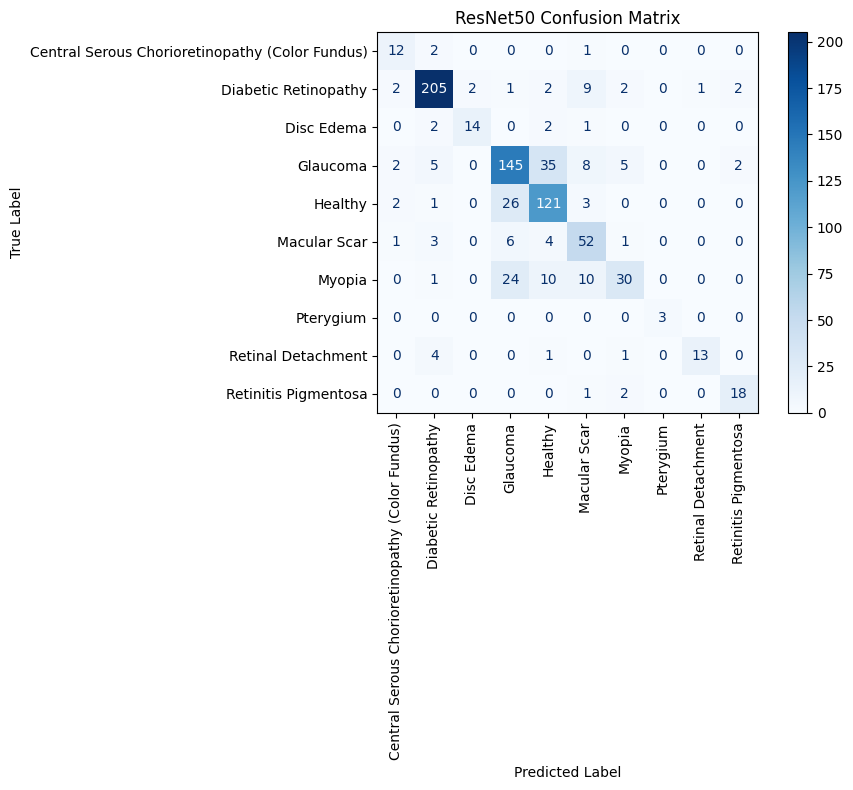

In [ ]:
# CONFUSION MATRIX - VALIDATION SET

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_val_true,
    y_val_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=True
)

ax.set_title("ResNet50 Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()